# Part A — Image Representation and Dataset Preparation

In [3]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Path to the extracted ORL dataset
dataset_path = Path("./archive")

# Find all subject folders (s1, s2, s3, ...)
subject_folders = sorted(
    [folder for folder in dataset_path.iterdir()
     if folder.is_dir() and folder.name.startswith("s")],
    key=lambda folder: int(folder.name[1:])
)

print("Number of subjects:", len(subject_folders))
print("First five subjects:",
      [folder.name for folder in subject_folders[:5]])


Number of subjects: 40
First five subjects: ['s1', 's2', 's3', 's4', 's5']


## Read and inspect one face image

Image file: 1.pgm
Image dimensions: (112, 92)
Minimum intensity: 11
Maximum intensity: 234
Data type: uint8


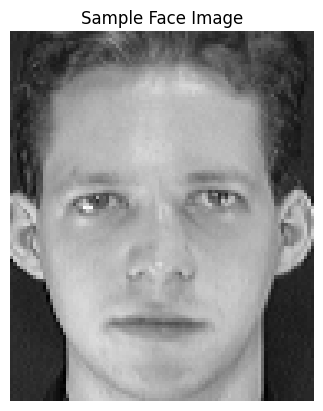

In [4]:
# Select the first image from subject s1
image_files = sorted(
    [file for file in subject_folders[0].iterdir()
     if file.is_file() and file.name != "README"]
)

image_path = image_files[0]

# Read the image in grayscale
image = Image.open(image_path).convert("L")
image_array = np.array(image)

print("Image file:", image_path.name)
print("Image dimensions:", image_array.shape)
print("Minimum intensity:", image_array.min())
print("Maximum intensity:", image_array.max())
print("Data type:", image_array.dtype)

plt.imshow(image_array, cmap="gray")
plt.title("Sample Face Image")
plt.axis("off")
plt.show()


## Load all images into a feature matrix

In [5]:
images = []
labels = []

for subject_folder in subject_folders:
    subject_label = int(subject_folder.name[1:])

    image_files = sorted(
        [file for file in subject_folder.iterdir()
            if file.is_file() and file.name != "README"]
    )

    for image_file in image_files:
        image = Image.open(image_file).convert("L")
        image_array = np.array(image)

        images.append(image_array.flatten())
        labels.append(subject_label)

X = np.array(images, dtype=np.float64)
y = np.array(labels)

print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Number of unique subjects:", len(np.unique(y)))
print("Images per subject:", np.unique(y, return_counts=True)[1])


Feature matrix shape: (400, 10304)
Label array shape: (400,)
Number of unique subjects: 40
Images per subject: [10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10]


## Reproducible train-test split

In [6]:
rng = np.random.default_rng(42)

train_indices = []
test_indices = []

for subject in np.unique(y):
    subject_indices = np.where(y == subject)[0]

    # Shuffle images for this subject
    subject_indices = rng.permutation(subject_indices)

    # 6 images for training, 4 for testing
    train_indices.extend(subject_indices[:6])
    test_indices.extend(subject_indices[6:])

# Create training and testing sets
train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in testing:", len(np.unique(y_test)))


Training feature matrix: (240, 10304)
Testing feature matrix: (160, 10304)
Training labels: (240,)
Testing labels: (160,)
Subjects in training: 40
Subjects in testing: 40


# Part B — PCA and Eigenfaces

## Mean face and mean centering

Mean face shape: (10304,)
Centered training matrix: (240, 10304)
Centered testing matrix: (160, 10304)
Mean of centered training data: 0.0


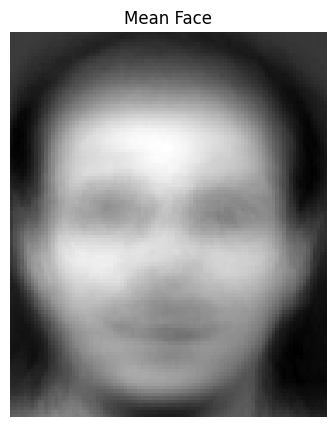

In [7]:
# Calculate the mean face from training data only
mean_face = np.mean(X_train, axis=0)

# Center the training and testing data using the training mean
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Mean face shape:", mean_face.shape)
print("Centered training matrix:", X_train_centered.shape)
print("Centered testing matrix:", X_test_centered.shape)
print("Mean of centered training data:", X_train_centered.mean())

# Visualize the mean face
mean_face_image = mean_face.reshape(112, 92)

plt.figure(figsize=(5, 5))
plt.imshow(mean_face_image, cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()


## PCA using covariance eigendecomposition

In [8]:
n_samples = X_train_centered.shape[0]

# Covariance in sample space: 240 x 240
covariance_small = (
    X_train_centered @ X_train_centered.T
) / (n_samples - 1)

# Eigenvalues and eigenvectors
eigenvalues_cov, eigenvectors_cov = np.linalg.eigh(
    covariance_small
)

# Sort in descending order
order = np.argsort(eigenvalues_cov)[::-1]
eigenvalues_cov = eigenvalues_cov[order]
eigenvectors_cov = eigenvectors_cov[:, order]

# Map eigenvectors into the original pixel space
eigenfaces_cov = X_train_centered.T @ eigenvectors_cov

# Normalize each eigenface
norms = np.linalg.norm(eigenfaces_cov, axis=0)
valid = norms > 1e-10

eigenfaces_cov = eigenfaces_cov[:, valid]
eigenvalues_cov = eigenvalues_cov[valid]

eigenfaces_cov = eigenfaces_cov / np.linalg.norm(
    eigenfaces_cov, axis=0
)

print("Covariance eigenfaces shape:", eigenfaces_cov.shape)
print("Largest eigenvalue:", eigenvalues_cov[0])

Covariance eigenfaces shape: (10304, 239)
Largest eigenvalue: 2809045.25406963


## PCA using Singular Value Decomposition

In [9]:
U, singular_values, VT = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Principal directions in pixel space
eigenfaces_svd = VT.T

# Eigenvalues corresponding to the principal directions
eigenvalues_svd = (
    singular_values ** 2
) / (n_samples - 1)

print("U shape:", U.shape)
print("Singular values shape:", singular_values.shape)
print("Eigenfaces from SVD:", eigenfaces_svd.shape)
print("Number of principal directions:", len(eigenvalues_svd))

U shape: (240, 240)
Singular values shape: (240,)
Eigenfaces from SVD: (10304, 240)
Number of principal directions: 240


## Compare the leading principal directions


In [10]:
num_compare = min(20, eigenfaces_cov.shape[1],
    eigenfaces_svd.shape[1])

similarities = np.abs(
    np.sum(
        eigenfaces_cov[:, :num_compare] *
        eigenfaces_svd[:, :num_compare],
        axis=0
    )
)

print("Absolute cosine similarities of leading directions:")
print(np.round(similarities, 6))

print("Average similarity:", similarities.mean())


Absolute cosine similarities of leading directions:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Average similarity: 0.9999999999999998


## Compare the leading 20 eigenvalues

In [11]:
num_compare = 20

print("Covariance eigenvalues:")
print(np.round(eigenvalues_cov[:num_compare], 4))

print("\nSVD eigenvalues:")
print(np.round(eigenvalues_svd[:num_compare], 4))

# Compare corresponding principal directions
similarities = np.abs(
    np.sum(
        eigenfaces_cov[:, :num_compare] *
        eigenfaces_svd[:, :num_compare],
        axis=0
    )
)

print("\nAbsolute cosine similarities:")
print(np.round(similarities, 6))

print("\nAverage similarity:", similarities.mean())


Covariance eigenvalues:
[2809045.2541 2123838.2565 1107672.4618  883851.5048  836550.0499
  515087.4166  414044.2858  386370.0895  328803.3066  284701.2269
  245992.2599  220874.7304  187444.7753  173131.1137  165465.2588
  159228.7906  148609.6706  136554.2948  126660.5011  115175.8016]

SVD eigenvalues:
[2809045.2541 2123838.2565 1107672.4618  883851.5048  836550.0499
  515087.4166  414044.2858  386370.0895  328803.3066  284701.2269
  245992.2599  220874.7304  187444.7753  173131.1137  165465.2588
  159228.7906  148609.6706  136554.2948  126660.5011  115175.8016]

Absolute cosine similarities:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Average similarity: 0.9999999999999998


## Explained variance

Components needed for 90% variance: 85
Variance preserved: 0.9008675965407708


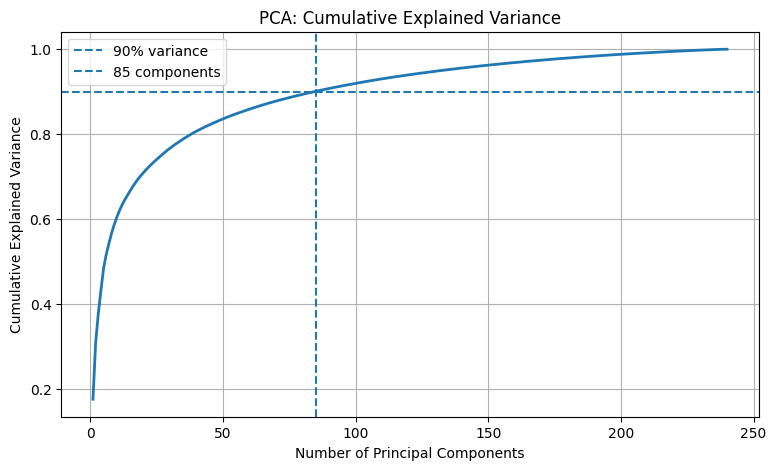

In [12]:
explained_variance_ratio = (
    eigenvalues_svd / eigenvalues_svd.sum()
)

cumulative_variance = np.cumsum(
    explained_variance_ratio
)

# Minimum number of components needed for 90% variance
n_components_90 = (
    np.searchsorted(cumulative_variance, 0.90) + 1
)

print("Components needed for 90% variance:",
      n_components_90)

print("Variance preserved:",
      cumulative_variance[n_components_90 - 1])

# Plot cumulative explained variance
plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)
plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% variance"
)
plt.axvline(
    x=n_components_90,
    linestyle="--",
    label=f"{n_components_90} components"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()


## Visualize the first 16 eigenfaces from SVD

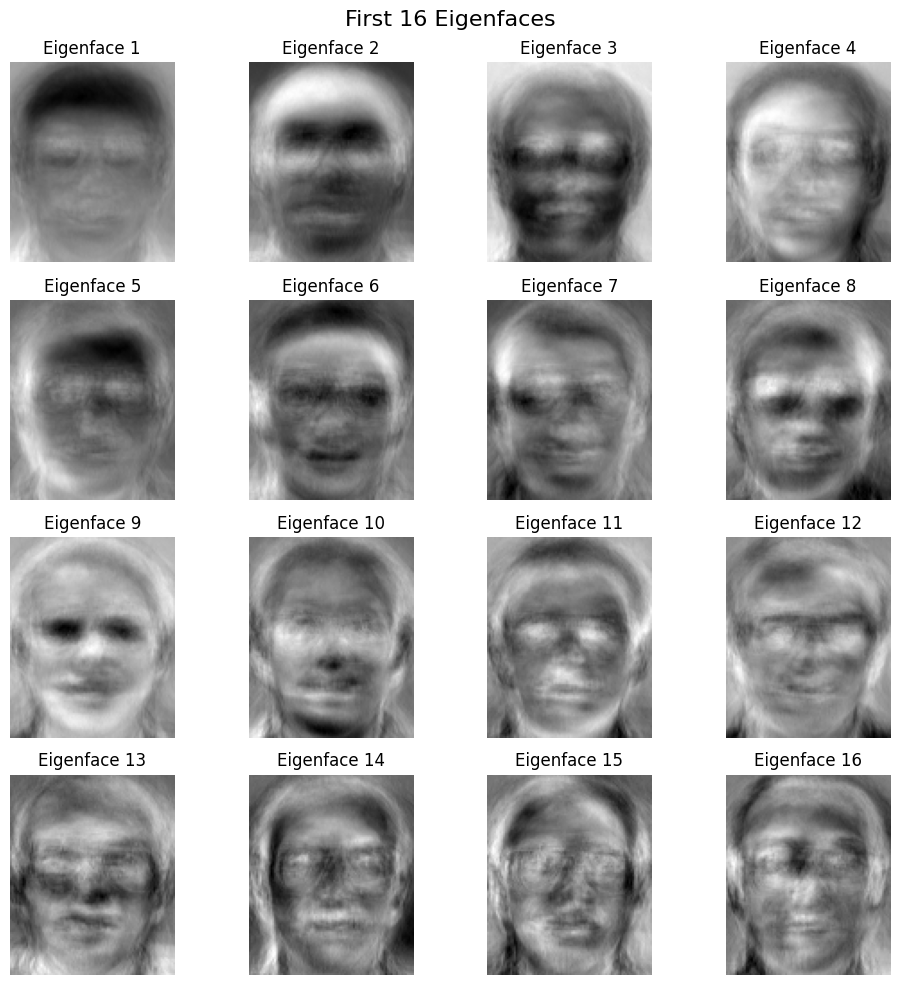

In [13]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    eigenface = eigenfaces_svd[:, i].reshape(112, 92)

    ax.imshow(eigenface, cmap="gray")
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.suptitle("First 16 Eigenfaces", fontsize=16)
plt.tight_layout()
plt.show()

## Project images into PCA space

In [14]:
# Use the first 85 principal components
k = n_components_90
principal_components = eigenfaces_svd[:, :k]

# Project training and testing data
X_train_pca = X_train_centered @ principal_components
X_test_pca = X_test_centered @ principal_components

print("Number of components:", k)
print("Training PCA representation:", X_train_pca.shape)
print("Testing PCA representation:", X_test_pca.shape)


Number of components: 85
Training PCA representation: (240, 85)
Testing PCA representation: (160, 85)


## Reconstruct sample faces

Reconstruction MSE for each face:
[388.38 529.27 412.15 342.3  462.87]
Average reconstruction MSE: 426.99


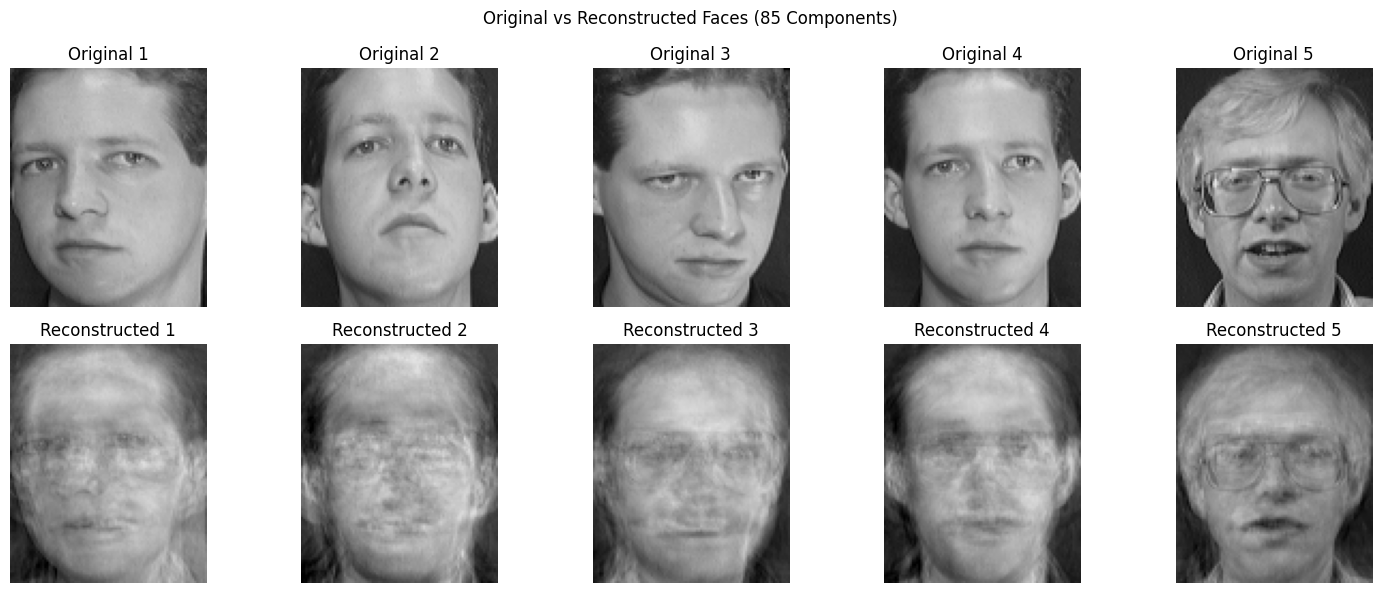

In [15]:
num_samples = 5

# Use five test images
original_faces = X_test[:num_samples]
test_centered = X_test_centered[:num_samples]

# Project and reconstruct
sample_pca = test_centered @ principal_components
reconstructed_faces = (
    sample_pca @ principal_components.T
) + mean_face

# Calculate reconstruction errors
mse_values = np.mean(
    (original_faces - reconstructed_faces) ** 2,
    axis=1
)

print("Reconstruction MSE for each face:")
print(np.round(mse_values, 2))
print("Average reconstruction MSE:", round(mse_values.mean(), 2))

# Display original and reconstructed images
fig, axes = plt.subplots(2, num_samples, figsize=(15, 6))

for i in range(num_samples):
    axes[0, i].imshow(
        original_faces[i].reshape(112, 92),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[0, i].set_title(f"Original {i + 1}")
    axes[0, i].axis("off")

    # Clip values only for display
    reconstructed_display = np.clip(
        reconstructed_faces[i], 0, 255
    ).reshape(112, 92)

    axes[1, i].imshow(
        reconstructed_display,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1, i].set_title(f"Reconstructed {i + 1}")
    axes[1, i].axis("off")

plt.suptitle("Original vs Reconstructed Faces (85 Components)")
plt.tight_layout()
plt.show()


## Representation storage comparison

In [16]:
original_features = X_train.shape[1]
reduced_features = X_train_pca.shape[1]

original_values = X_train.shape[0] * original_features
reduced_values = X_train_pca.shape[0] * reduced_features

compression_ratio = original_values / reduced_values
storage_reduction = (
    1 - reduced_values / original_values
) * 100

print("Original values:", original_values)
print("Reduced values:", reduced_values)
print("Compression ratio:", round(compression_ratio, 2), "to 1")
print("Representation size reduction:",
      round(storage_reduction, 2), "%")


Original values: 2472960
Reduced values: 20400
Compression ratio: 121.22 to 1
Representation size reduction: 99.18 %


# Part C — Face Recognition

## Raw-pixel nearest-neighbor baseline

In [17]:
raw_distances = np.sqrt(
    np.sum(
        (X_test[:, None, :] - X_train[None, :, :]) ** 2,
        axis=2
    )
)

raw_nearest_indices = np.argmin(raw_distances, axis=1)
y_pred_raw = y_train[raw_nearest_indices]

raw_accuracy = np.mean(y_pred_raw == y_test)

print("Raw-pixel nearest-neighbor accuracy:",
      round(raw_accuracy * 100, 2), "%")
print("Correct predictions:",
      np.sum(y_pred_raw == y_test), "out of", len(y_test))


Raw-pixel nearest-neighbor accuracy: 96.88 %
Correct predictions: 155 out of 160


## PCA-space nearest-neighbor recognition

In [18]:
pca_distances = np.sqrt(
    np.sum(
        (X_test_pca[:, None, :] - X_train_pca[None, :, :]) ** 2,
        axis=2
    )
)

pca_nearest_indices = np.argmin(pca_distances, axis=1)
y_pred_pca = y_train[pca_nearest_indices]

pca_accuracy = np.mean(y_pred_pca == y_test)

print("PCA nearest-neighbor accuracy:",
      round(pca_accuracy * 100, 2), "%")
print("Correct predictions:",
      np.sum(y_pred_pca == y_test), "out of", len(y_test))


PCA nearest-neighbor accuracy: 96.25 %
Correct predictions: 154 out of 160


## Compare Recognition results 

Method                            Accuracy
------------------------------------------
Raw pixels                          96.88%
PCA features (85)                   96.25%


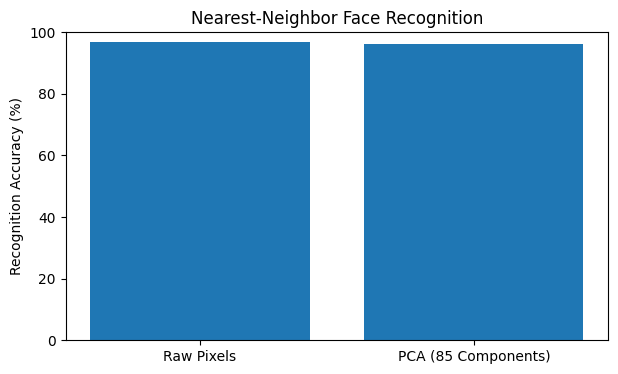

In [19]:
print(f"{'Method':<30}{'Accuracy':>12}")
print("-" * 42)
print(f"{'Raw pixels':<30}{raw_accuracy * 100:>11.2f}%")
print(f"{'PCA features (85)':<30}{pca_accuracy * 100:>11.2f}%")

plt.figure(figsize=(7, 4))
plt.bar(
    ["Raw Pixels", "PCA (85 Components)"],
    [raw_accuracy * 100, pca_accuracy * 100]
)
plt.ylabel("Recognition Accuracy (%)")
plt.title("Nearest-Neighbor Face Recognition")
plt.ylim(0, 100)
plt.show()


## Visualize correct and incorrect PCA matches

Correct predictions: 154
Incorrect predictions: 6


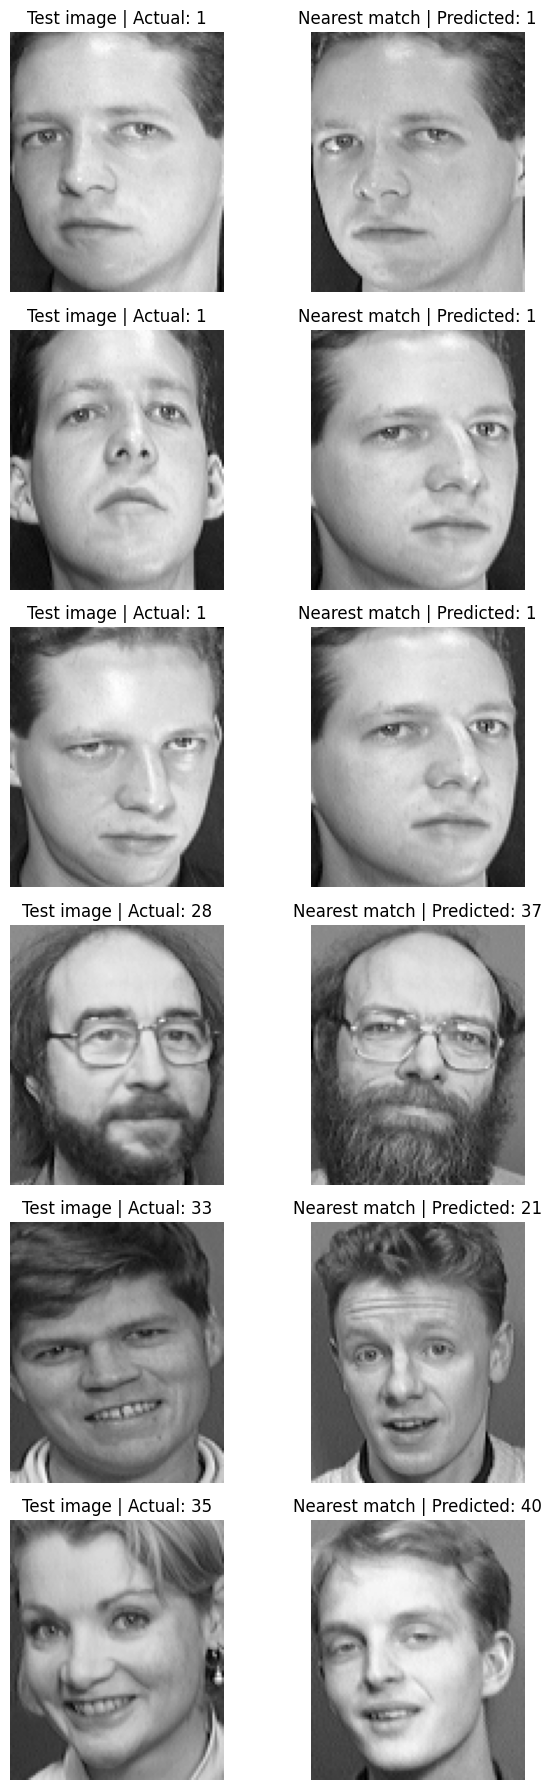

In [20]:
import matplotlib.pyplot as plt
import numpy as np

correct_indices = np.where(y_pred_pca == y_test)[0]
wrong_indices = np.where(y_pred_pca != y_test)[0]

print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(wrong_indices))

# Display up to 3 correct and 3 incorrect predictions
selected_indices = list(correct_indices[:3]) + list(wrong_indices[:3])

fig, axes = plt.subplots(len(selected_indices), 2, figsize=(7, 3 * len(selected_indices)))

if len(selected_indices) == 1:
    axes = np.array([axes])

for row, test_idx in enumerate(selected_indices):
    train_idx = pca_nearest_indices[test_idx]

    # Test image
    axes[row, 0].imshow(X_test[test_idx].reshape(112, 92), cmap="gray")
    axes[row, 0].set_title(f"Test image | Actual: {y_test[test_idx]}")
    axes[row, 0].axis("off")

    # Nearest training image
    axes[row, 1].imshow(X_train[train_idx].reshape(112, 92), cmap="gray")
    axes[row, 1].set_title(f"Nearest match | Predicted: {y_pred_pca[test_idx]}")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

# Part D: Traditional Machine Learning Classifiers on PCA Features.

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# KNN classifier
knn_model = KNeighborsClassifier(n_neighbors=1)
knn_model.fit(X_train_pca, y_train)
y_pred_knn = knn_model.predict(X_test_pca)

# Logistic Regression classifier
lr_model = LogisticRegression(max_iter=2000, random_state=42)
lr_model.fit(X_train_pca, y_train)
y_pred_lr = lr_model.predict(X_test_pca)

# Support Vector Machine classifier
svm_model = SVC(kernel="rbf", C=10, gamma="scale")
svm_model.fit(X_train_pca, y_train)
y_pred_svm = svm_model.predict(X_test_pca)

# Compare accuracy
results = {
    "PCA Nearest Neighbor": accuracy_score(y_test, y_pred_pca),
    "KNN (k=1)": accuracy_score(y_test, y_pred_knn),
    "Logistic Regression": accuracy_score(y_test, y_pred_lr),
    "SVM (RBF)": accuracy_score(y_test, y_pred_svm)
}

for method, accuracy in results.items():
    print(f"{method}: {accuracy * 100:.2f}%")


PCA Nearest Neighbor: 96.25%
KNN (k=1): 96.25%
Logistic Regression: 96.88%
SVM (RBF): 97.50%


## Compare classifier accuracy

              Method  Accuracy (%)
PCA Nearest Neighbor        96.250
           KNN (k=1)        96.250
 Logistic Regression        96.875
           SVM (RBF)        97.500


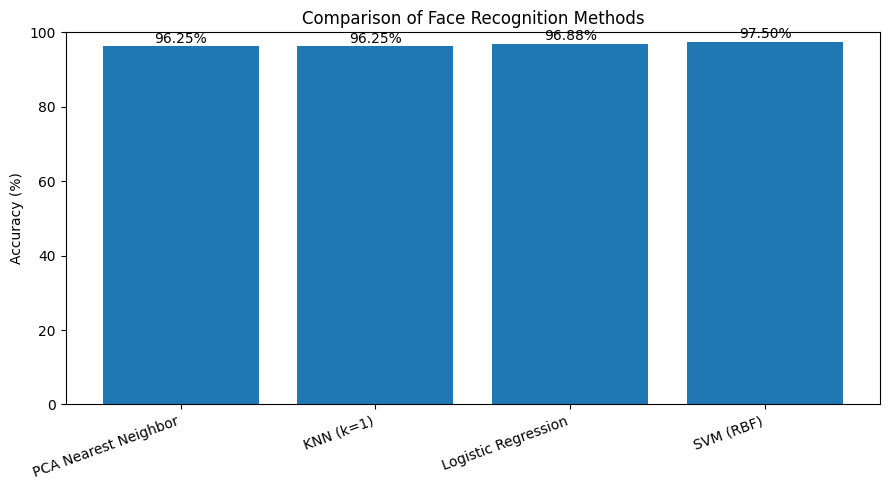

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

results_df = pd.DataFrame({
    "Method": list(results.keys()),
    "Accuracy (%)": [accuracy * 100 for accuracy in results.values()]
})

print(results_df.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.bar(results_df["Method"], results_df["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.title("Comparison of Face Recognition Methods")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")

for i, value in enumerate(results_df["Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()


## Test different numbers of PCA components

In [23]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

component_counts = [20, 40, 60, 85, 120]
tuning_results = []

for k in component_counts:
    # Project images onto the first k principal components
    components = eigenfaces_svd[:, :k]

    X_train_k = X_train_centered @ components
    X_test_k = X_test_centered @ components

    # KNN
    knn = KNeighborsClassifier(n_neighbors=1)
    knn.fit(X_train_k, y_train)
    knn_acc = accuracy_score(y_test, knn.predict(X_test_k))

    # Logistic Regression
    lr = LogisticRegression(max_iter=2000, random_state=42)
    lr.fit(X_train_k, y_train)
    lr_acc = accuracy_score(y_test, lr.predict(X_test_k))

    # SVM
    svm = SVC(kernel="rbf", C=10, gamma="scale")
    svm.fit(X_train_k, y_train)
    svm_acc = accuracy_score(y_test, svm.predict(X_test_k))

    tuning_results.append({
        "Components": k,
        "KNN Accuracy (%)": knn_acc * 100,
        "Logistic Regression Accuracy (%)": lr_acc * 100,
        "SVM Accuracy (%)": svm_acc * 100
    })

tuning_df = pd.DataFrame(tuning_results)
print(tuning_df.round(2).to_string(index=False))


 Components  KNN Accuracy (%)  Logistic Regression Accuracy (%)  SVM Accuracy (%)
         20             94.38                             97.50             97.50
         40             96.88                             97.50             98.12
         60             96.88                             96.88             98.12
         85             96.25                             96.88             97.50
        120             96.88                             97.50             97.50


In [24]:

accuracy_columns = [
    "KNN Accuracy (%)",
    "Logistic Regression Accuracy (%)",
    "SVM Accuracy (%)"
]

best_accuracy = tuning_df[accuracy_columns].to_numpy().max()

print("Best observed configurations:")

for _, row in tuning_df.iterrows():
    for classifier in accuracy_columns:
        if np.isclose(row[classifier], best_accuracy):
            print(
                f"Components: {int(row['Components'])} | "
                f"Classifier: {classifier} | "
                f"Accuracy: {row[classifier]:.2f}%"
            )

print("\nOriginal-pixel NN accuracy:", round(raw_accuracy * 100, 2), "%")
print("PCA NN accuracy:", round(pca_accuracy * 100, 2), "%")


Best observed configurations:
Components: 40 | Classifier: SVM Accuracy (%) | Accuracy: 98.12%
Components: 60 | Classifier: SVM Accuracy (%) | Accuracy: 98.12%

Original-pixel NN accuracy: 96.88 %
PCA NN accuracy: 96.25 %


### Part D: Traditional Machine Learning Classifier Comparison

The following three classical machine learning classifiers were considered in the problem: K-Nearest Neighbors (KNN), Logistic Regression and Support Vector Machine (SVM) with RBF kernel.

Using 85 principal components, SVM showed the best test accuracy of 97.50%, followed by Logistic Regression with 96.88% and KNN with 96.25%. The nearest neighbor classifier using PCA reached 96.25% accuracy.

In addition, another experiment examined the classifiers using 20, 40, 60, 85 and 120 principal components. The highest test accuracy was 98.12% and was shown by SVM using 40 and 60 components and by Logistic Regression with 120 components. KNN reached maximum accuracy of 96.88%.

It means that classifier performance depends on the number of used principal components. Increase in the number of components does not necessarily improve the accuracy. In particular, SVM demonstrated the highest possible accuracy using 40 components.

Thus, it can be concluded that PCA decreased the dimensionality of face images significantly while maintaining the accuracy. Since the obtained results correspond to a single train/test split, the models should be re-trained using cross-validation or other replicable split.